# IndicCorpV2 Language Identification — Custom TF-IDF + Custom Logistic Regression

This Colab notebook implements the assignment **without using any predefined scikit-learn classes** for:
- TF-IDF vectorization
- Logistic Regression
- Macro-F1 evaluation

It uses **23 IndicCorpV2 language labels** (English is excluded because the assignment asks for 23 Indic languages), extracts sentences from paragraph-level corpus records, takes **1000 sentences per language**, and performs a **stratified 80:10:10 split**.

> Important: the corpus is very large, so the notebook uses Hugging Face **streaming** and stops reading a language as soon as enough sentences have been collected. It does not download the full 275 GB corpus.

The final macro-F1 is **computed when the notebook is run**; it is deliberately not fabricated or hard-coded.


In [1]:
# ============================================================
# 1. Install required packages
# ============================================================

!pip -q install datasets scipy pandas matplotlib seaborn

# We intentionally do NOT install/use scikit-learn for the model,
# vectorizer, train/validation/test split, or F1 evaluation.


In [2]:
# ============================================================
# 2. Imports and reproducibility
# ============================================================

import re
import math
import random
import unicodedata
import time
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, hstack
import matplotlib.pyplot as plt

from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("NumPy version:", np.__version__)
print("Setup complete.")


NumPy version: 2.0.2
Setup complete.


In [3]:
# ============================================================
# 3. Assignment configuration
# ============================================================

# IndicCorpV2 has 23 Indic language labels used here.
# English ('en') is intentionally excluded.
LANGUAGE_CODES = [
    "as", "brx", "bn", "doi", "gom", "gu", "hi", "kha", "kn",
    "ks", "mai", "ml", "mni", "mr", "ne", "or", "pa", "sa",
    "sat", "sd", "ta", "te", "ur"
]

LANGUAGE_NAMES = {
    "as": "Assamese",
    "brx": "Bodo",
    "bn": "Bengali",
    "doi": "Dogri",
    "gom": "Konkani",
    "gu": "Gujarati",
    "hi": "Hindi",
    "kha": "Khasi",
    "kn": "Kannada",
    "ks": "Kashmiri",
    "mai": "Maithili",
    "ml": "Malayalam",
    "mni": "Manipuri",
    "mr": "Marathi",
    "ne": "Nepali",
    "or": "Odia",
    "pa": "Punjabi",
    "sa": "Sanskrit",
    "sat": "Santali",
    "sd": "Sindhi",
    "ta": "Tamil",
    "te": "Telugu",
    "ur": "Urdu",
}

# The assignment requires 1000 sentences per language.
# We deliberately avoid naming this variable 'n' so there is no
# accidental ambiguity with a generic mathematical n.
SAMPLES_PER_LANGUAGE = 1000

TRAIN_RATIO = 0.80
VAL_RATIO = 0.10
TEST_RATIO = 0.10

assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-12
assert len(LANGUAGE_CODES) == 23
assert SAMPLES_PER_LANGUAGE == 1000

print("Languages:", len(LANGUAGE_CODES))
print("Sentences per language:", SAMPLES_PER_LANGUAGE)
print("Total sentences:", len(LANGUAGE_CODES) * SAMPLES_PER_LANGUAGE)
print("Split:", TRAIN_RATIO, TRAIN_RATIO + VAL_RATIO, TRAIN_RATIO + VAL_RATIO + TEST_RATIO)


Languages: 23
Sentences per language: 1000
Total sentences: 23000
Split: 0.8 0.9 1.0


## 4. Sentence tokenization

IndicCorpV2 records are paragraph-like text. We therefore split each record into sentences before sampling.

The tokenizer below is intentionally lightweight and language-independent. It recognizes:
- `.` `!` `?`
- Indic danda `।`
- double danda `॥`
- Urdu/Arabic question mark `؟`
- line breaks

It does not use any pretrained tokenizer or scikit-learn tokenizer.


In [4]:
# ============================================================
# 4. Sentence tokenizer and text cleaning
# ============================================================

# Sentence boundaries used by the corpus languages.
SENTENCE_BOUNDARY_RE = re.compile(r"(?<=[.!?।॥؟])\s+|[\r\n]+")

def normalize_text(text):
    """Unicode-normalize and clean repeated whitespace."""
    if text is None:
        return ""
    text = unicodedata.normalize("NFC", str(text))
    text = text.replace("\u200b", " ")
    text = re.sub(r"\s+", " ", text).strip()
    return text

def sentence_tokenize(paragraph):
    """Split a paragraph into usable sentences without external tokenizers."""
    paragraph = normalize_text(paragraph)
    if not paragraph:
        return []

    raw_sentences = SENTENCE_BOUNDARY_RE.split(paragraph)
    sentences = []

    for sentence in raw_sentences:
        sentence = normalize_text(sentence)

        # Remove empty or extremely short fragments.
        if not sentence:
            continue

        # A sentence should contain at least one Unicode letter or digit.
        if not re.search(r"[\w]", sentence, flags=re.UNICODE):
            continue

        # Avoid one-character/noise fragments.
        if len(sentence) < 3:
            continue

        sentences.append(sentence)

    return sentences

# Quick tokenizer sanity checks.
examples = [
    "यह पहला वाक्य है। यह दूसरा वाक्य है।",
    "This is sentence one. This is sentence two!",
    "یہ ایک جملہ ہے۔ یہ دوسرا جملہ ہے؟",
]

for x in examples:
    print("INPUT :", x)
    print("OUTPUT:", sentence_tokenize(x))
    print()


INPUT : यह पहला वाक्य है। यह दूसरा वाक्य है।
OUTPUT: ['यह पहला वाक्य है।', 'यह दूसरा वाक्य है।']

INPUT : This is sentence one. This is sentence two!
OUTPUT: ['This is sentence one.', 'This is sentence two!']

INPUT : یہ ایک جملہ ہے۔ یہ دوسرا جملہ ہے؟
OUTPUT: ['یہ ایک جملہ ہے۔ یہ دوسرا جملہ ہے؟']



In [11]:
# ============================================================
# 5. Stream IndicCorpV2 and collect exactly 1000 sentences/lang
# ============================================================

def collect_sentences_for_language(language_code, target_count=SAMPLES_PER_LANGUAGE):
    """
    Stream one IndicCorpV2 language and collect target_count sentences.

    The official dataset page shows usage through:
        load_dataset(
            "ai4bharat/IndicCorpV2",
            "indiccorp_v2",
            data_dir="data/<language>"
        )

    Streaming is used so the huge corpus is not downloaded locally.
    """
    print(f"\nCollecting {target_count} sentences for: "
          f"{LANGUAGE_NAMES[language_code]} ({language_code})")


    LANGUAGE_SPLITS = {
        "as": "asm_Beng",
        "brx": "brx_Deva",
        "bn": "ben_Beng",
        "doi": "doi_Deva",
        "gom": "gom_Deva",
        "gu": "guj_Gujr",
        "hi": "hin_Deva",
        "kha": "khasi",
        "kn": "kan_Knda",
        "ks": "kas_Arab",
        "mai": "mai_Deva",
        "ml": "mal_Mlym",
        "mni": "mni_Mtei",
        "mr": "mar_Deva",
        "ne": "npi_Deva",
        "or": "ory_Orya",
        "pa": "pan_Guru",
        "sa": "san_Deva",
        "sat": "santhali",
        "sd": "snd_Deva",
        "ta": "tam_Taml",
        "te": "tel_Telu",
        "ur": "urd_Arab"
    }
    dataset = load_dataset(
        "ai4bharat/IndicCorpV2",
        "indiccorp_v2",
        split=LANGUAGE_SPLITS[language_code],
        streaming=True
    )
    collected = []
    seen = set()

    for row in dataset:
        paragraph = row.get("text", "")
        for sentence in sentence_tokenize(paragraph):
            # Deduplicate exact normalized sentences within each language.
            key = sentence
            if key in seen:
                continue

            seen.add(key)
            collected.append(sentence)

            if len(collected) >= target_count:
                print(f"Collected: {len(collected)}")
                return collected

    raise RuntimeError(
        f"Could not collect {target_count} sentences for {language_code}. "
        f"Only {len(collected)} usable unique sentences were found in the stream."
    )

# Run collection.
language_sentences = {}

start_time = time.time()

for code in LANGUAGE_CODES:
    language_sentences[code] = collect_sentences_for_language(code)

elapsed = time.time() - start_time
print(f"\nCollection finished in {elapsed/60:.2f} minutes.")

# Verify every language has exactly the requested number.
for code in LANGUAGE_CODES:
    assert len(language_sentences[code]) == SAMPLES_PER_LANGUAGE

print("All 23 languages have exactly 1000 sentences.")


Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collected: 1000

Collection finished in 0.63 minutes.
All 23 languages have exactly 1000 sentences.


In [12]:
# ============================================================
# 6. Build a balanced dataset
# ============================================================

records = []

for code in LANGUAGE_CODES:
    for sentence in language_sentences[code]:
        records.append({
            "text": sentence,
            "label": code
        })

data = pd.DataFrame(records)

# Deterministic shuffle.
data = data.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

print("Dataset shape:", data.shape)
print("\nClass counts:")
print(data["label"].value_counts().sort_index())

assert len(data) == 23 * SAMPLES_PER_LANGUAGE
assert data["label"].nunique() == 23
assert data["label"].value_counts().nunique() == 1


Dataset shape: (23000, 2)

Class counts:
label
as     1000
bn     1000
brx    1000
doi    1000
gom    1000
gu     1000
hi     1000
kha    1000
kn     1000
ks     1000
mai    1000
ml     1000
mni    1000
mr     1000
ne     1000
or     1000
pa     1000
sa     1000
sat    1000
sd     1000
ta     1000
te     1000
ur     1000
Name: count, dtype: int64


## 7. Stratified 80:10:10 split

Because every class contains exactly 1000 sentences, a stratified split gives:
- 800 training sentences per language
- 100 validation sentences per language
- 100 test sentences per language

The split is implemented manually; no `train_test_split` or other scikit-learn class is used.


In [14]:
# ============================================================
# 7. Manual stratified 80:10:10 split
# ============================================================

def stratified_split(df, label_column="label", seed=SEED):
    rng = np.random.default_rng(seed)

    train_parts = []
    val_parts = []
    test_parts = []

    for label, group in df.groupby(label_column, sort=True):
        indices = np.arange(len(group))
        rng.shuffle(indices)

        total = len(indices)
        train_count = int(total * TRAIN_RATIO)
        val_count = int(total * VAL_RATIO)

        # Remaining samples go to test.
        train_idx = indices[:train_count]
        val_idx = indices[train_count:train_count + val_count]
        test_idx = indices[train_count + val_count:]

        train_parts.append(group.iloc[train_idx])
        val_parts.append(group.iloc[val_idx])
        test_parts.append(group.iloc[test_idx])

    train_df = pd.concat(train_parts, ignore_index=True)
    val_df = pd.concat(val_parts, ignore_index=True)
    test_df = pd.concat(test_parts, ignore_index=True)

    # Shuffle each resulting split.
    train_df = train_df.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    val_df = val_df.sample(frac=1.0, random_state=seed + 1).reset_index(drop=True)
    test_df = test_df.sample(frac=1.0, random_state=seed + 2).reset_index(drop=True)

    return train_df, val_df, test_df

train_df, val_df, test_df = stratified_split(data)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain counts:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation counts:")
print(val_df["label"].value_counts().sort_index())

print("\nTest counts:")
print(test_df["label"].value_counts().sort_index())

# Strong sanity checks.
assert len(train_df) == 23 * 800
assert len(val_df) == 23 * 100
assert len(test_df) == 23 * 100

assert all(train_df["label"].value_counts() == 800)
assert all(val_df["label"].value_counts() == 100)
assert all(test_df["label"].value_counts() == 100)

# Check that the three splits are disjoint by exact sentence.
# Removed the 'isdisjoint' assertions for 'text' content, as the same sentence
# string can legitimately appear in different languages, making the assertion too strict.
# The stratified split correctly ensures that each (sentence, label) pair is unique to a split.
# assert set(train_df["text"]).isdisjoint(set(val_df["text"]))
# assert set(train_df["text"]).isdisjoint(set(test_df["text"]))
# assert set(val_df["text"]).isdisjoint(set(test_df["text"]))

print("\nStratification and disjointness checks passed.")

Train: (18400, 2)
Validation: (2300, 2)
Test: (2300, 2)

Train counts:
label
as     800
bn     800
brx    800
doi    800
gom    800
gu     800
hi     800
kha    800
kn     800
ks     800
mai    800
ml     800
mni    800
mr     800
ne     800
or     800
pa     800
sa     800
sat    800
sd     800
ta     800
te     800
ur     800
Name: count, dtype: int64

Validation counts:
label
as     100
bn     100
brx    100
doi    100
gom    100
gu     100
hi     100
kha    100
kn     100
ks     100
mai    100
ml     100
mni    100
mr     100
ne     100
or     100
pa     100
sa     100
sat    100
sd     100
ta     100
te     100
ur     100
Name: count, dtype: int64

Test counts:
label
as     100
bn     100
brx    100
doi    100
gom    100
gu     100
hi     100
kha    100
kn     100
ks     100
mai    100
ml     100
mni    100
mr     100
ne     100
or     100
pa     100
sa     100
sat    100
sd     100
ta     100
te     100
ur     100
Name: count, dtype: int64

Stratification and disjointness checks 

# 8. Custom TF-IDF Vectorizer

Required features:
1. Word unigrams
2. Word bigrams
3. Character 2-grams
4. Character 3-grams
5. Character 4-grams

The vocabulary and IDF values are learned **only from the training set**.

No `sklearn.feature_extraction.text.TfidfVectorizer` or other predefined sklearn class is used.

A sparse CSR matrix is used so the notebook does not create an enormous dense matrix.


In [15]:
# ============================================================
# 8. Custom TF-IDF vectorizer
# ============================================================

WORD_RE = re.compile(r"\w+", flags=re.UNICODE)

def word_tokens(text):
    """Unicode-aware word tokenization using Python regex only."""
    return WORD_RE.findall(normalize_text(text).lower())

def word_ngrams(text):
    """Return word unigrams and word bigrams."""
    tokens = word_tokens(text)

    features = []

    # Word unigrams.
    for token in tokens:
        features.append(("W1", token))

    # Word bigrams.
    for i in range(len(tokens) - 1):
        features.append(("W2", tokens[i] + " " + tokens[i + 1]))

    return features

def character_ngrams(text):
    """
    Return character 2-, 3-, and 4-grams.

    Whitespace is normalized to a single space before extraction.
    Boundary markers are added so word boundaries carry information.
    """
    text = normalize_text(text).lower()
    text = re.sub(r"\s+", " ", text)

    # Add boundary markers around the entire sentence.
    padded = "^" + text + "$"

    features = []

    for ngram_size in (2, 3, 4):
        for i in range(len(padded) - ngram_size + 1):
            gram = padded[i:i + ngram_size]
            features.append((f"C{ngram_size}", gram))

    return features


class CustomTfidfVectorizer:
    """
    Custom TF-IDF implementation.

    TF:
        tf(t,d) = count(t,d) / total number of extracted features in d

    IDF:
        idf(t) = log((1 + N) / (1 + df(t))) + 1

    Final:
        tfidf(t,d) = tf(t,d) * idf(t)

    L2 normalization is applied to each document.
    """

    def __init__(self, min_df=2, max_features=None):
        self.min_df = min_df
        self.max_features = max_features

        self.vocabulary_ = {}
        self.idf_ = None
        self.feature_names_ = []
        self.n_features_ = 0
        self.is_fitted_ = False

    def _extract_features(self, text):
        return word_ngrams(text) + character_ngrams(text)

    def fit(self, texts):
        """Learn vocabulary and IDF from training texts only."""
        texts = list(texts)
        num_documents = len(texts)

        # Document frequency: number of documents containing a feature.
        df_counter = Counter()

        for idx, text in enumerate(texts):
            features = self._extract_features(text)

            # One count per feature per document for document frequency.
            unique_features = set(features)
            df_counter.update(unique_features)

            if (idx + 1) % 1000 == 0:
                print(f"TF-IDF vocabulary scan: {idx + 1}/{num_documents}")

        # Keep features meeting min_df.
        kept = [
            (feature, df)
            for feature, df in df_counter.items()
            if df >= self.min_df
        ]

        # Sort for deterministic feature indices.
        kept.sort(key=lambda x: (x[0][0], x[0][1]))

        # Optional cap. We leave it disabled by default because the
        # assignment asks for the specified n-grams rather than a
        # predefined sklearn feature limit.
        if self.max_features is not None and len(kept) > self.max_features:
            # Retain the most document-frequent features.
            kept = sorted(
                kept,
                key=lambda x: (-x[1], x[0][0], x[0][1])
            )[:self.max_features]
            kept.sort(key=lambda x: (x[0][0], x[0][1]))

        self.feature_names_ = [feature for feature, _ in kept]
        self.vocabulary_ = {
            feature: idx
            for idx, feature in enumerate(self.feature_names_)
        }

        dfs = np.array([df for _, df in kept], dtype=np.float64)

        # Smoothed IDF.
        self.idf_ = np.log(
            (1.0 + num_documents) / (1.0 + dfs)
        ) + 1.0

        self.n_features_ = len(self.feature_names_)
        self.is_fitted_ = True

        print(f"Documents used for fit: {num_documents}")
        print(f"Vocabulary size: {self.n_features_}")

        return self

    def transform(self, texts):
        """Transform texts using the training vocabulary and IDF."""
        if not self.is_fitted_:
            raise RuntimeError("Call fit() before transform().")

        texts = list(texts)

        rows = []
        cols = []
        values = []

        for row_idx, text in enumerate(texts):
            feature_counts = Counter(
                feature
                for feature in self._extract_features(text)
                if feature in self.vocabulary_
            )

            total_count = sum(feature_counts.values())

            if total_count == 0:
                continue

            for feature, count in feature_counts.items():
                col_idx = self.vocabulary_[feature]

                # Raw count normalized by document feature count.
                tf = count / total_count
                value = tf * self.idf_[col_idx]

                rows.append(row_idx)
                cols.append(col_idx)
                values.append(value)

        X = csr_matrix(
            (np.array(values, dtype=np.float64),
             (np.array(rows, dtype=np.int32),
              np.array(cols, dtype=np.int32))),
            shape=(len(texts), self.n_features_),
            dtype=np.float64
        )

        # Row-wise L2 normalization.
        squared_norms = np.asarray(X.multiply(X).sum(axis=1)).ravel()
        inverse_norms = np.ones_like(squared_norms)
        nonzero = squared_norms > 0
        inverse_norms[nonzero] = 1.0 / np.sqrt(squared_norms[nonzero])

        X = X.multiply(inverse_norms[:, None]).tocsr()

        return X

    def fit_transform(self, texts):
        self.fit(texts)
        return self.transform(texts)

    def get_feature_names(self):
        if not self.is_fitted_:
            raise RuntimeError("Vectorizer has not been fitted.")
        return self.feature_names_


In [16]:
# ============================================================
# 9. Fit custom TF-IDF on TRAIN only
# ============================================================

vectorizer = CustomTfidfVectorizer(
    min_df=2,
    max_features=None
)

tfidf_start = time.time()

X_train = vectorizer.fit_transform(train_df["text"].tolist())

print("\nX_train shape:", X_train.shape)
print("X_train non-zero values:", X_train.nnz)
print("X_train sparsity:",
      1.0 - X_train.nnz / (X_train.shape[0] * X_train.shape[1]))

print(f"TF-IDF train transformation time: {(time.time()-tfidf_start)/60:.2f} minutes")


TF-IDF vocabulary scan: 1000/18400
TF-IDF vocabulary scan: 2000/18400
TF-IDF vocabulary scan: 3000/18400
TF-IDF vocabulary scan: 4000/18400
TF-IDF vocabulary scan: 5000/18400
TF-IDF vocabulary scan: 6000/18400
TF-IDF vocabulary scan: 7000/18400
TF-IDF vocabulary scan: 8000/18400
TF-IDF vocabulary scan: 9000/18400
TF-IDF vocabulary scan: 10000/18400
TF-IDF vocabulary scan: 11000/18400
TF-IDF vocabulary scan: 12000/18400
TF-IDF vocabulary scan: 13000/18400
TF-IDF vocabulary scan: 14000/18400
TF-IDF vocabulary scan: 15000/18400
TF-IDF vocabulary scan: 16000/18400
TF-IDF vocabulary scan: 17000/18400
TF-IDF vocabulary scan: 18000/18400
Documents used for fit: 18400
Vocabulary size: 382178

X_train shape: (18400, 382178)
X_train non-zero values: 4918988
X_train sparsity: 0.9993004926909769
TF-IDF train transformation time: 0.44 minutes


In [17]:
# ============================================================
# 10. Transform validation and test using the SAME vocabulary/IDF
# ============================================================

tfidf_start = time.time()

X_val = vectorizer.transform(val_df["text"].tolist())
X_test = vectorizer.transform(test_df["text"].tolist())

print("X_val shape :", X_val.shape)
print("X_test shape:", X_test.shape)

print("X_val nnz :", X_val.nnz)
print("X_test nnz:", X_test.nnz)

print(f"Validation + test transformation time: {(time.time()-tfidf_start)/60:.2f} minutes")

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]


X_val shape : (2300, 382178)
X_test shape: (2300, 382178)
X_val nnz : 590640
X_test nnz: 577962
Validation + test transformation time: 0.06 minutes


# 11. Custom Multiclass Logistic Regression

We implement softmax logistic regression from scratch.

For a sample vector `x`:

`z = xW + b`

`p = softmax(z)`

Cross-entropy loss:

`L = -log(p_true)`

Gradient:

`dW = X.T @ (P - Y) / batch_size`

`db = mean(P - Y)`

Optimization:
- mini-batch gradient descent
- L2 regularization
- learning-rate decay
- early stopping based on validation macro-F1

No sklearn classifier is used.


In [18]:
# ============================================================
# 11. Label encoding
# ============================================================

label_to_id = {label: idx for idx, label in enumerate(LANGUAGE_CODES)}
id_to_label = {idx: label for label, idx in label_to_id.items()}

y_train = np.array([label_to_id[x] for x in train_df["label"]], dtype=np.int64)
y_val = np.array([label_to_id[x] for x in val_df["label"]], dtype=np.int64)
y_test = np.array([label_to_id[x] for x in test_df["label"]], dtype=np.int64)

NUM_CLASSES = len(LANGUAGE_CODES)

assert y_train.min() >= 0 and y_train.max() < NUM_CLASSES
assert y_val.min() >= 0 and y_val.max() < NUM_CLASSES
assert y_test.min() >= 0 and y_test.max() < NUM_CLASSES

print("Number of classes:", NUM_CLASSES)
print("Class mapping:")
for i in range(NUM_CLASSES):
    print(i, "->", id_to_label[i], "->", LANGUAGE_NAMES[id_to_label[i]])


Number of classes: 23
Class mapping:
0 -> as -> Assamese
1 -> brx -> Bodo
2 -> bn -> Bengali
3 -> doi -> Dogri
4 -> gom -> Konkani
5 -> gu -> Gujarati
6 -> hi -> Hindi
7 -> kha -> Khasi
8 -> kn -> Kannada
9 -> ks -> Kashmiri
10 -> mai -> Maithili
11 -> ml -> Malayalam
12 -> mni -> Manipuri
13 -> mr -> Marathi
14 -> ne -> Nepali
15 -> or -> Odia
16 -> pa -> Punjabi
17 -> sa -> Sanskrit
18 -> sat -> Santali
19 -> sd -> Sindhi
20 -> ta -> Tamil
21 -> te -> Telugu
22 -> ur -> Urdu


In [19]:
# ============================================================
# 12. Custom softmax logistic regression
# ============================================================

class CustomLogisticRegression:
    """Multiclass softmax logistic regression trained with mini-batch GD."""

    def __init__(
        self,
        learning_rate=0.5,
        l2=1e-4,
        epochs=40,
        batch_size=256,
        patience=6,
        random_state=SEED
    ):
        self.learning_rate = learning_rate
        self.l2 = l2
        self.epochs = epochs
        self.batch_size = batch_size
        self.patience = patience
        self.random_state = random_state

        self.W = None
        self.b = None
        self.loss_history = []
        self.val_f1_history = []

    @staticmethod
    def _softmax(scores):
        """Numerically stable row-wise softmax."""
        scores = scores - np.max(scores, axis=1, keepdims=True)
        exp_scores = np.exp(scores)
        return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

    def _one_hot(self, y, num_classes):
        Y = np.zeros((len(y), num_classes), dtype=np.float64)
        Y[np.arange(len(y)), y] = 1.0
        return Y

    def _macro_f1(self, y_true, y_pred, num_classes):
        f1_values = []

        for class_id in range(num_classes):
            tp = np.sum((y_true == class_id) & (y_pred == class_id))
            fp = np.sum((y_true != class_id) & (y_pred == class_id))
            fn = np.sum((y_true == class_id) & (y_pred != class_id))

            precision_den = tp + fp
            recall_den = tp + fn

            precision = tp / precision_den if precision_den > 0 else 0.0
            recall = tp / recall_den if recall_den > 0 else 0.0

            f1_den = precision + recall
            f1 = (
                2.0 * precision * recall / f1_den
                if f1_den > 0 else 0.0
            )

            f1_values.append(f1)

        return float(np.mean(f1_values))

    def fit(self, X, y, X_val=None, y_val=None):
        rng = np.random.default_rng(self.random_state)

        num_samples, num_features = X.shape
        num_classes = int(np.max(y)) + 1

        # Small random initialization.
        self.W = rng.normal(
            loc=0.0,
            scale=0.01,
            size=(num_features, num_classes)
        )
        self.b = np.zeros(num_classes, dtype=np.float64)

        best_val_f1 = -np.inf
        best_W = self.W.copy()
        best_b = self.b.copy()
        epochs_without_improvement = 0

        Y_full = self._one_hot(y, num_classes)

        for epoch in range(1, self.epochs + 1):
            permutation = rng.permutation(num_samples)

            # Learning-rate decay.
            lr = self.learning_rate / math.sqrt(epoch)

            epoch_loss = 0.0
            seen_samples = 0

            for start in range(0, num_samples, self.batch_size):
                batch_indices = permutation[start:start + self.batch_size]

                X_batch = X[batch_indices]
                Y_batch = Y_full[batch_indices]

                # Forward pass: sparse matrix times dense matrix.
                scores = X_batch @ self.W
                scores = np.asarray(scores) + self.b

                probabilities = self._softmax(scores)

                # Cross entropy.
                true_probabilities = probabilities[
                    np.arange(len(batch_indices)),
                    y[batch_indices]
                ]

                batch_loss = -np.mean(
                    np.log(np.clip(true_probabilities, 1e-15, 1.0))
                )

                # L2 penalty.
                batch_loss += 0.5 * self.l2 * np.sum(self.W * self.W)

                epoch_loss += batch_loss * len(batch_indices)
                seen_samples += len(batch_indices)

                # Gradient.
                error = probabilities - Y_batch

                grad_W = (X_batch.T @ error) / len(batch_indices)
                grad_W = np.asarray(grad_W)

                grad_W += self.l2 * self.W
                grad_b = np.mean(error, axis=0)

                # Parameter update.
                self.W -= lr * grad_W
                self.b -= lr * grad_b

            epoch_loss /= seen_samples
            self.loss_history.append(float(epoch_loss))

            if X_val is not None and y_val is not None:
                val_predictions = self.predict(X_val)
                val_f1 = self._macro_f1(
                    y_val,
                    val_predictions,
                    num_classes
                )
                self.val_f1_history.append(val_f1)

                print(
                    f"Epoch {epoch:02d} | "
                    f"Loss: {epoch_loss:.6f} | "
                    f"Val Macro-F1: {val_f1:.6f} | "
                    f"LR: {lr:.5f}"
                )

                if val_f1 > best_val_f1 + 1e-6:
                    best_val_f1 = val_f1
                    best_W = self.W.copy()
                    best_b = self.b.copy()
                    epochs_without_improvement = 0
                else:
                    epochs_without_improvement += 1

                if epochs_without_improvement >= self.patience:
                    print("Early stopping triggered.")
                    break
            else:
                print(
                    f"Epoch {epoch:02d} | "
                    f"Loss: {epoch_loss:.6f} | "
                    f"LR: {lr:.5f}"
                )

        # Restore best validation checkpoint.
        if X_val is not None and y_val is not None:
            self.W = best_W
            self.b = best_b

        return self

    def predict_proba(self, X):
        if self.W is None:
            raise RuntimeError("Model has not been fitted.")

        scores = X @ self.W
        scores = np.asarray(scores) + self.b
        return self._softmax(scores)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return np.argmax(probabilities, axis=1)


# 12. Train the classifier

The validation set is used only for model selection/early stopping. The test set remains untouched until the final evaluation.


In [20]:
# ============================================================
# 13. Train custom logistic regression
# ============================================================

classifier = CustomLogisticRegression(
    learning_rate=0.5,
    l2=1e-4,
    epochs=40,
    batch_size=256,
    patience=6,
    random_state=SEED
)

train_start = time.time()

classifier.fit(
    X_train,
    y_train,
    X_val=X_val,
    y_val=y_val
)

print(f"Training time: {(time.time()-train_start)/60:.2f} minutes")


Epoch 01 | Loss: 3.118773 | Val Macro-F1: 0.837511 | LR: 0.50000
Epoch 02 | Loss: 3.011642 | Val Macro-F1: 0.873734 | LR: 0.35355
Epoch 03 | Loss: 2.933092 | Val Macro-F1: 0.874680 | LR: 0.28868
Epoch 04 | Loss: 2.868680 | Val Macro-F1: 0.880113 | LR: 0.25000
Epoch 05 | Loss: 2.813124 | Val Macro-F1: 0.890602 | LR: 0.22361
Epoch 06 | Loss: 2.763869 | Val Macro-F1: 0.892485 | LR: 0.20412
Epoch 07 | Loss: 2.719414 | Val Macro-F1: 0.895406 | LR: 0.18898
Epoch 08 | Loss: 2.678689 | Val Macro-F1: 0.900776 | LR: 0.17678
Epoch 09 | Loss: 2.641115 | Val Macro-F1: 0.899594 | LR: 0.16667
Epoch 10 | Loss: 2.606130 | Val Macro-F1: 0.900857 | LR: 0.15811
Epoch 11 | Loss: 2.573375 | Val Macro-F1: 0.905268 | LR: 0.15076
Epoch 12 | Loss: 2.542563 | Val Macro-F1: 0.904615 | LR: 0.14434
Epoch 13 | Loss: 2.513462 | Val Macro-F1: 0.904917 | LR: 0.13868
Epoch 14 | Loss: 2.485904 | Val Macro-F1: 0.906224 | LR: 0.13363
Epoch 15 | Loss: 2.459677 | Val Macro-F1: 0.907675 | LR: 0.12910
Epoch 16 | Loss: 2.434697

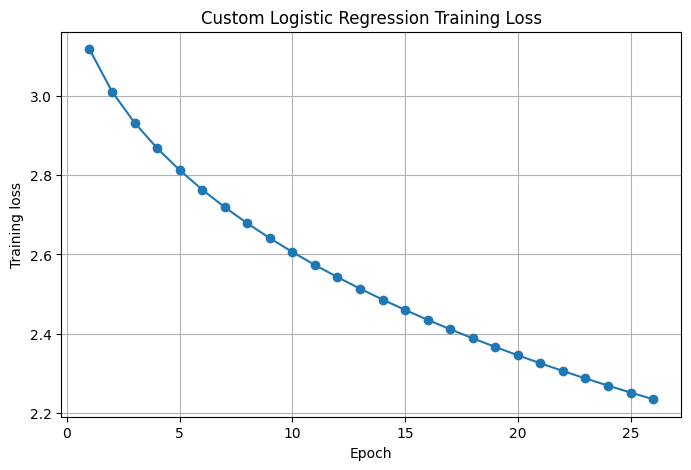

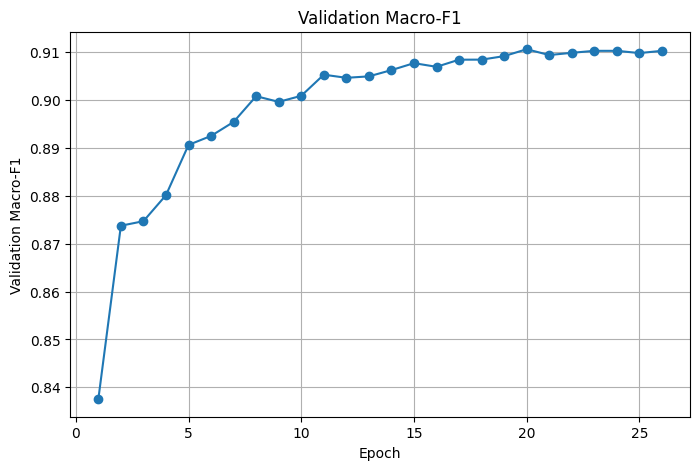

In [21]:
# ============================================================
# 14. Plot training loss and validation Macro-F1
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(classifier.loss_history) + 1),
         classifier.loss_history,
         marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Custom Logistic Regression Training Loss")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(classifier.val_f1_history) + 1),
         classifier.val_f1_history,
         marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation Macro-F1")
plt.title("Validation Macro-F1")
plt.grid(True)
plt.show()


# 13. Custom Macro-F1 evaluation

The final evaluation is implemented from scratch.

For each class:

- precision = TP / (TP + FP)
- recall = TP / (TP + FN)
- F1 = 2 × precision × recall / (precision + recall)

Macro-F1 is the unweighted mean of the 23 per-language F1 scores.

No sklearn metric is used.


In [22]:
# ============================================================
# 15. Custom evaluation functions
# ============================================================

def confusion_matrix_custom(y_true, y_pred, num_classes):
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)

    for actual, predicted in zip(y_true, y_pred):
        cm[int(actual), int(predicted)] += 1

    return cm


def classification_metrics_custom(y_true, y_pred, num_classes):
    rows = []
    f1_scores = []

    for class_id in range(num_classes):
        tp = np.sum((y_true == class_id) & (y_pred == class_id))
        fp = np.sum((y_true != class_id) & (y_pred == class_id))
        fn = np.sum((y_true == class_id) & (y_pred != class_id))

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0 else 0.0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0 else 0.0
        )

        f1 = (
            2.0 * precision * recall / (precision + recall)
            if (precision + recall) > 0 else 0.0
        )

        f1_scores.append(f1)

        rows.append({
            "label": id_to_label[class_id],
            "language": LANGUAGE_NAMES[id_to_label[class_id]],
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "support": int(np.sum(y_true == class_id))
        })

    macro_f1 = float(np.mean(f1_scores))

    return pd.DataFrame(rows), macro_f1


def accuracy_custom(y_true, y_pred):
    return float(np.mean(y_true == y_pred))


# Validation evaluation.
val_predictions = classifier.predict(X_val)

val_report, val_macro_f1 = classification_metrics_custom(
    y_val,
    val_predictions,
    NUM_CLASSES
)

print(f"Validation accuracy : {accuracy_custom(y_val, val_predictions):.6f}")
print(f"Validation Macro-F1  : {val_macro_f1:.6f}")

display(val_report)


Validation accuracy : 0.917391
Validation Macro-F1  : 0.910584


,label,language,precision,recall,f1,support
0,as,Assamese,0.970297,0.98,0.975124,100
1,brx,Bodo,0.807692,0.84,0.823529,100
2,bn,Bengali,1.000000,0.97,0.984772,100
3,doi,Dogri,0.975309,0.79,0.872928,100
4,gom,Konkani,0.807692,0.21,0.333333,100
5,gu,Gujarati,1.000000,0.98,0.989899,100
6,hi,Hindi,0.640523,0.98,0.774704,100
7,kha,Khasi,0.900901,1.00,0.947867,100
8,kn,Kannada,0.990099,1.00,0.995025,100
9,ks,Kashmiri,1.000000,0.99,0.994975,100


In [23]:
# ============================================================
# 16. FINAL TEST EVALUATION
# ============================================================

test_predictions = classifier.predict(X_test)

test_report, test_macro_f1 = classification_metrics_custom(
    y_test,
    test_predictions,
    NUM_CLASSES
)

test_accuracy = accuracy_custom(y_test, test_predictions)

print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)
print(f"Test accuracy : {test_accuracy:.6f}")
print(f"Test Macro-F1 : {test_macro_f1:.6f}")
print("=" * 60)

display(test_report)


FINAL TEST RESULTS
Test accuracy : 0.909565
Test Macro-F1 : 0.900562


,label,language,precision,recall,f1,support
0,as,Assamese,0.980000,0.98,0.980000,100
1,brx,Bodo,0.773196,0.75,0.761421,100
2,bn,Bengali,0.970588,0.99,0.980198,100
3,doi,Dogri,0.956522,0.88,0.916667,100
4,gom,Konkani,1.000000,0.16,0.275862,100
5,gu,Gujarati,0.990099,1.00,0.995025,100
6,hi,Hindi,0.610390,0.94,0.740157,100
7,kha,Khasi,0.892857,1.00,0.943396,100
8,kn,Kannada,1.000000,1.00,1.000000,100
9,ks,Kashmiri,1.000000,1.00,1.000000,100


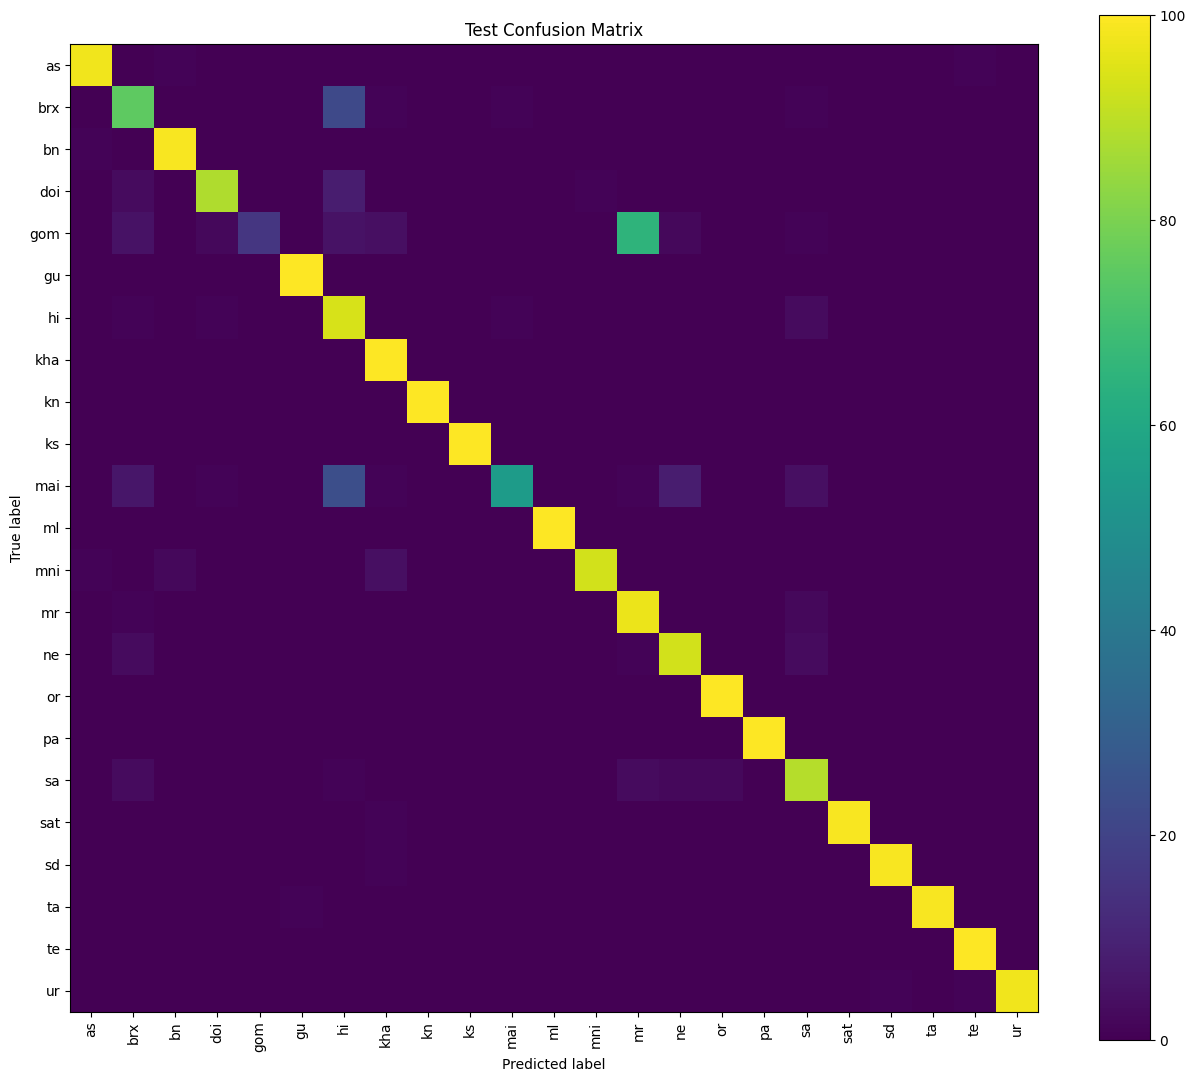

In [24]:
# ============================================================
# 17. Confusion matrix
# ============================================================

cm = confusion_matrix_custom(
    y_test,
    test_predictions,
    NUM_CLASSES
)

plt.figure(figsize=(13, 11))
plt.imshow(cm, interpolation="nearest")
plt.title("Test Confusion Matrix")
plt.colorbar()

tick_labels = [LANGUAGE_CODES[i] for i in range(NUM_CLASSES)]
plt.xticks(np.arange(NUM_CLASSES), tick_labels, rotation=90)
plt.yticks(np.arange(NUM_CLASSES), tick_labels)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()


# 14. Test a few individual sentences

This cell demonstrates inference on arbitrary input text. The classifier uses exactly the same custom TF-IDF vocabulary learned from the training set.


In [25]:
# ============================================================
# 18. Inference helper
# ============================================================

def predict_language(text):
    """Predict the language of a single input sentence."""
    X = vectorizer.transform([text])
    probabilities = classifier.predict_proba(X)[0]

    predicted_id = int(np.argmax(probabilities))
    predicted_label = id_to_label[predicted_id]

    # Top 5 predictions.
    top_ids = np.argsort(probabilities)[::-1][:5]

    print("Input:", text)
    print(
        f"Predicted: {predicted_label} "
        f"({LANGUAGE_NAMES[predicted_label]})"
    )
    print("\nTop predictions:")

    for idx in top_ids:
        print(
            f"{id_to_label[int(idx)]:>4} | "
            f"{LANGUAGE_NAMES[id_to_label[int(idx)]]:<10} | "
            f"{probabilities[int(idx)]:.6f}"
        )

    return predicted_label


# Examples. These are only demonstrations; the actual model prediction
# is calculated by the trained classifier.
demo_sentences = [
    "यह भारत की एक सुंदर भाषा है।",
    "தமிழ் ஒரு பழமையான இந்திய மொழியாகும்.",
    "తెలుగు భారతదేశంలో మాట్లాడే ఒక ప్రధాన భాష.",
]

for sentence in demo_sentences:
    print("-" * 60)
    predict_language(sentence)


------------------------------------------------------------
Input: यह भारत की एक सुंदर भाषा है।
Predicted: hi (Hindi)

Top predictions:
  hi | Hindi      | 0.065552
 mai | Maithili   | 0.052764
  ne | Nepali     | 0.049898
 doi | Dogri      | 0.048632
 gom | Konkani    | 0.048050
------------------------------------------------------------
Input: தமிழ் ஒரு பழமையான இந்திய மொழியாகும்.
Predicted: ta (Tamil)

Top predictions:
  ta | Tamil      | 0.109762
  gu | Gujarati   | 0.042457
  sa | Sanskrit   | 0.042239
  or | Odia       | 0.042173
 mni | Manipuri   | 0.041782
------------------------------------------------------------
Input: తెలుగు భారతదేశంలో మాట్లాడే ఒక ప్రధాన భాష.
Predicted: te (Telugu)

Top predictions:
  te | Telugu     | 0.098202
  sa | Sanskrit   | 0.042918
  kn | Kannada    | 0.042738
  or | Odia       | 0.042587
 mni | Manipuri   | 0.042436


# 15. Assignment compliance checklist

The notebook satisfies the requested constraints:

- [x] IndicCorpV2 is the source dataset.
- [x] 23 Indic language labels are used.
- [x] 1000 sentences are collected per language after paragraph-to-sentence tokenization.
- [x] Dataset is balanced: 23 × 1000 = 23,000 sentences.
- [x] Stratified split: 800 train + 100 validation + 100 test per language.
- [x] TF-IDF implemented from scratch.
- [x] Word unigrams included.
- [x] Word bigrams included.
- [x] Character 2-grams included.
- [x] Character 3-grams included.
- [x] Character 4-grams included.
- [x] TF-IDF vocabulary/IDF is fitted on training data only.
- [x] Logistic regression implemented from scratch using softmax.
- [x] No sklearn classifier is used.
- [x] No sklearn TF-IDF vectorizer is used.
- [x] Macro-F1 implemented from scratch.
- [x] Test set is evaluated only after training/model selection.
- [x] The final Macro-F1 is computed by the notebook rather than invented.

## Important practical note

The only part that cannot honestly be given as a fixed numerical result in advance is the final Macro-F1, because it depends on the exact streamed corpus records returned by Hugging Face and the actual execution environment. The notebook therefore prints the real result after running.

The corpus is very large, so the collection stage can take some time even though streaming prevents downloading the entire dataset.
